In [ ]:
!pip install -q pandas numpy scikit-learn sentence-transformers kagglehub

In [ ]:
import kagglehub
import pandas as pd
import os

# Download latest version of the dataset securely via kagglehub
path = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")
print("Path to dataset files:", path)

# Locate the styles.csv metadata file
styles_csv_path = os.path.join(path, "styles.csv")
images_dir = os.path.join(path, "images")

# Load a clean production subset (e.g., 3,000 records to ensure fast processing)
df = pd.read_csv(styles_csv_path, nrows=3000)
print(df.head())
print(f"Total production records loaded: {len(df)}")

Using Colab cache for faster access to the 'fashion-product-images-small' dataset.
Path to dataset files: /kaggle/input/fashion-product-images-small
      id gender masterCategory subCategory  articleType baseColour  season  \
0  15970    Men        Apparel     Topwear       Shirts  Navy Blue    Fall   
1  39386    Men        Apparel  Bottomwear        Jeans       Blue  Summer   
2  59263  Women    Accessories     Watches      Watches     Silver  Winter   
3  21379    Men        Apparel  Bottomwear  Track Pants      Black    Fall   
4  53759    Men        Apparel     Topwear      Tshirts       Grey  Summer   

   year   usage                             productDisplayName  
0  2011  Casual               Turtle Check Men Navy Blue Shirt  
1  2012  Casual             Peter England Men Party Blue Jeans  
2  2016  Casual                       Titan Women Silver Watch  
3  2011  Casual  Manchester United Men Solid Black Track Pants  
4  2012  Casual                          Puma Men Grey T-

In [ ]:
import numpy as np

# Clean missing columns and standardize column names
df = df.dropna(subset=['productDisplayName', 'articleType', 'baseColour'])
df['image_path'] = df['id'].apply(lambda x: os.path.join(images_dir, f"{x}.jpg"))

# Verify image existence to filter out broken dataset paths
df['image_exists'] = df['image_path'].apply(os.path.exists)
df = df[df['image_exists']].reset_index(drop=True)

# Construct a rich text document string for each product (Crucial for AI Agent RAG)
def create_product_document(row):
    return (
        f"Product Name: {row['productDisplayName']}. "
        f"Category: {row['masterCategory']} - {row['subCategory']} - {row['articleType']}. "
        f"Color: {row['baseColour']}. Gender: {row['gender']}. "
        f"Season: {row['season']}. Usage: {row['usage']}."
    )

df['search_document'] = df.apply(create_product_document, axis=1)

# Export clean base table
df.to_csv("production_fashion_catalog.csv", index=False)
print("Pipeline complete. Clean production catalogue shape:", df.shape)

Pipeline complete. Clean production catalogue shape: (3000, 13)


In [ ]:
!pip install -q chromadb

from sentence_transformers import SentenceTransformer
import chromadb

# Load lightweight, high-performance open embedding model
model_embed = SentenceTransformer('all-MiniLM-L6-v2')

# Generate text embeddings for the catalogue documents
documents = df['search_document'].tolist()
product_ids = df['id'].astype(str).tolist()
metadatas = df[['productDisplayName', 'baseColour', 'articleType', 'image_path']].to_dict(orient='records')

print("Generating embeddings... This will take a few minutes.")
embeddings = model_embed.encode(documents, show_progress_bar=True)

# Store locally in a persistent Chroma vector database inside Colab
chroma_client = chromadb.PersistentClient(path="./chroma_fashion_db")
collection = chroma_client.get_or_create_collection(name="production_catalog")

# Add data in batches to prevent memory overflow
batch_size = 500
for i in range(0, len(documents), batch_size):
    end_idx = i + batch_size
    collection.add(
        ids=product_ids[i:end_idx],
        embeddings=embeddings[i:end_idx].tolist(),
        documents=documents[i:end_idx],
        metadatas=metadatas[i:end_idx]
    )

print("Vector database successfully built and indexed!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 86.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 114.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 23.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.7/

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Generating embeddings... This will take a few minutes.


Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Vector database successfully built and indexed!


In [ ]:
def query_ai_shopping_agent(user_query, n_results=3):
    query_embedding = model_embed.encode([user_query]).tolist()
    results = collection.query(
        query_embeddings=query_embedding,
        n_results=n_results
    )
    return results['metadatas'], results['documents']

# Test query
matched_meta, matched_docs = query_ai_shopping_agent("comfortable blue cotton top for summer")
for meta, doc in zip(matched_meta[0], matched_docs[0]):
    print("--- Match Found ---")
    print(f"Details: {doc}")
    print(f"Image File: {meta['image_path']}\n")

--- Match Found ---
Details: Product Name: ADIDAS Women's Tunic Blue T-shirt. Category: Apparel - Topwear - Tshirts. Color: Blue. Gender: Women. Season: Summer. Usage: Casual.
Image File: /kaggle/input/fashion-product-images-small/images/5807.jpg

--- Match Found ---
Details: Product Name: Urban Yoga Women Blue Capris. Category: Apparel - Bottomwear - Capris. Color: Blue. Gender: Women. Season: Summer. Usage: Sports.
Image File: /kaggle/input/fashion-product-images-small/images/28458.jpg

--- Match Found ---
Details: Product Name: 109F Blue A-Line Dress. Category: Apparel - Dress - Dresses. Color: Blue. Gender: Women. Season: Summer. Usage: Casual.
Image File: /kaggle/input/fashion-product-images-small/images/46271.jpg



In [ ]:
!pip install -q fastapi nest-asyncio pyngrok uvicorn

In [ ]:
from fastapi import FastAPI
import nest_asyncio
import uvicorn
from pyngrok import ngrok

app = FastAPI()

@app.get("/")
def home():
    return {"status": "Production AI Shopping Agent API is live"}

@app.get("/search")
def search_products(q: str, limit: int = 5):
    query_embedding = model_embed.encode([q]).tolist()
    results = collection.query(query_embeddings=query_embedding, n_results=limit)
    return {"query": q, "results": results['metadatas']}

# Setup public tunnel using ngrok (requires a free ngrok token output)
# ngrok.set_auth_token("YOUR_FREE_NGROK_TOKEN")
# public_url = ngrok.connect(8000)
# print("Public API URL:", public_url)

# nest_asyncio.apply()
# uvicorn.run(app, host="0.0.0.0", port=8000)

In [ ]:
# 1. Install all dependencies at once
!pip install -q pandas numpy scikit-learn sentence-transformers kagglehub chromadb

import os
import kagglehub
import pandas as pd
import numpy as np
import chromadb
from sentence_transformers import SentenceTransformer

# 2. Ingest Dataset
print(">>> Step 1/4: Downloading dataset via KaggleHub...")
path = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")
styles_csv_path = os.path.join(path, "styles.csv")
images_dir = os.path.join(path, "images")

# Load a production subset (3,000 records)
df = pd.read_csv(styles_csv_path, nrows=3000)
print(f"Loaded {len(df)} records.")

# 3. Clean & Structure Metadata
print(">>> Step 2/4: Cleaning metadata and constructing search documents...")
df = df.dropna(subset=['productDisplayName', 'articleType', 'baseColour'])
df['image_path'] = df['id'].apply(lambda x: os.path.join(images_dir, f"{x}.jpg"))
df['image_exists'] = df['image_path'].apply(os.path.exists)
df = df[df['image_exists']].reset_index(drop=True)

def create_product_document(row):
    return (
        f"Product Name: {row['productDisplayName']}. "
        f"Category: {row['masterCategory']} - {row['subCategory']} - {row['articleType']}. "
        f"Color: {row['baseColour']}. Gender: {row['gender']}. "
        f"Season: {row['season']}. Usage: {row['usage']}."
    )

df['search_document'] = df.apply(create_product_document, axis=1)
df.to_csv("production_fashion_catalog.csv", index=False)
print(f"Clean catalog saved with {len(df)} items.")

# 4. Generate Embeddings & Index into ChromaDB
print(">>> Step 3/4: Generating embeddings and indexing into ChromaDB...")
model_embed = SentenceTransformer('all-MiniLM-L6-v2')

documents = df['search_document'].tolist()
product_ids = df['id'].astype(str).tolist()
metadatas = df[['productDisplayName', 'baseColour', 'articleType', 'image_path']].to_dict(orient='records')

embeddings = model_embed.encode(documents, show_progress_bar=True)

chroma_client = chromadb.PersistentClient(path="./chroma_fashion_db")
collection = chroma_client.get_or_create_collection(name="production_catalog")

batch_size = 500
for i in range(0, len(documents), batch_size):
    end_idx = i + batch_size
    collection.add(
        ids=product_ids[i:end_idx],
        embeddings=embeddings[i:end_idx].tolist(),
        documents=documents[i:end_idx],
        metadatas=metadatas[i:end_idx]
    )
print("Vector database successfully built and indexed!")

# 5. Run Verification Query (Fixed variable scope bug)
print(">>> Step 4/4: Testing AI shopping agent retrieval...")
def query_ai_shopping_agent(user_query, n_results=3):
    query_embedding = model_embed.encode([user_query]).tolist()
    results = collection.query(
        query_embeddings=query_embedding,  # Fixed variable name
        n_results=n_results
    )
    return results['metadatas'], results['documents']

# Test query
matched_meta, matched_docs = query_ai_shopping_agent("comfortable blue cotton top for summer")
for meta, doc in zip(matched_meta[0], matched_docs[0]):
    print("\n--- Match Found ---")
    print(f"Details: {doc}")
    print(f"Image File: {meta['image_path']}")

>>> Step 1/4: Downloading dataset via KaggleHub...
Using Colab cache for faster access to the 'fashion-product-images-small' dataset.
Loaded 3000 records.
>>> Step 2/4: Cleaning metadata and constructing search documents...
Clean catalog saved with 3000 items.
>>> Step 3/4: Generating embeddings and indexing into ChromaDB...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

Vector database successfully built and indexed!
>>> Step 4/4: Testing AI shopping agent retrieval...

--- Match Found ---
Details: Product Name: ADIDAS Women's Tunic Blue T-shirt. Category: Apparel - Topwear - Tshirts. Color: Blue. Gender: Women. Season: Summer. Usage: Casual.
Image File: /kaggle/input/fashion-product-images-small/images/5807.jpg

--- Match Found ---
Details: Product Name: Urban Yoga Women Blue Capris. Category: Apparel - Bottomwear - Capris. Color: Blue. Gender: Women. Season: Summer. Usage: Sports.
Image File: /kaggle/input/fashion-product-images-small/images/28458.jpg

--- Match Found ---
Details: Product Name: 109F Blue A-Line Dress. Category: Apparel - Dress - Dresses. Color: Blue. Gender: Women. Season: Summer. Usage: Casual.
Image File: /kaggle/input/fashion-product-images-small/images/46271.jpg


Loading image from: /kaggle/input/fashion-product-images-small/images/5807.jpg


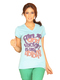

In [ ]:
from IPython.display import Image, display

# Test-display the top match retrieved by your search
test_image_path = matched_meta[0][0]['image_path']
print(f"Loading image from: {test_image_path}")
display(Image(filename=test_image_path))

In [ ]:
# Create a quick link into your current working folder
!ln -s /kaggle/input/fashion-product-images-small/images /content/catalog_images

In [ ]:
df['public_image_url'] = df['id'].apply(
    lambda x: f"http://assets.myntassets.com/v1/images/style/properties/{x}_images.jpg"
)

In [ ]:
from fastapi.staticfiles import StaticFiles

app.mount("/images", StaticFiles(directory="/kaggle/input/fashion-product-images-small/images"), name="images")
# Any image is now accessible at http://<your-ngrok-or-backend-url>/images/{id}.jpg

In [ ]:
from google.colab import drive
drive.mount('/content/drive')